# Emploment in AI, Data Science and software Development

**Name:** Abhinav Borgohain
**Student number:** 2023287
**Dataset:** BLS Occupational Employment Wage Statistics, May 2023

**GitHub:** https://github.com/AbhinavBorgohain/AI_Employment_Analysis_DVC_CA1

**Video explanation:** https://drive.google.com/file/d/1KV9ToECp14oAmeTif4vvafRcVIfAZt6E/view?usp=sharing

In [4]:
import pandas as pd 

# Loading  the data and preserving identification codes as text.
df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    dtype={
        "AREA": str,
        "AREA_TYPE": str,
        "NAICS": str,
        "OWN_CODE": str,
        "OCC_CODE": str
    }
)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 413327
Columns: 32


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## Data inspection and preparation

This analysis looks at six occupations related to AI research, data science and software development. These are broad job groups. The data does not show how many people in each group work specifically in AI.

The analysis uses figures across all industries, covering private and government employment. National and state figures are kept separate to avoid counting the same jobs twice.

The selected numerical columns are converted to numbers. Entries that cannot be converted are treated as missing values. They are not changed to zero. Wages are shown in US dollars.

In [7]:
df.info()

print("Exact duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  object
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  object
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  object
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

In [12]:
occupation_codes = [
  "15-1221",  # Computer and Information Research Scientists
  "15-1243", # Database Architects
  "15-1251", # Computer Programmers
  "15-1252",  # Software Developers
  "15-2041",  # Statisticians
  "15-2051"   # Data Scientists
]


df["AREA_TYPE"] = df["AREA_TYPE"].astype(str)


selected = df.loc[
    df["OCC_CODE"].isin(occupation_codes)
    & df["AREA_TYPE"].isin(["1", "2"])
    & (df["NAICS"] == "000000")
    & (df["OWN_CODE"] == "1235")
    & (df["O_GROUP"] == "detailed")
].copy()

print("Selected rows:", len(selected))

Selected rows: 301


In [13]:

duplicates_removed = selected.duplicated().sum()
selected = selected.drop_duplicates()


numeric_columns = ["TOT_EMP", "A_MEAN", "A_MEDIAN", "LOC_QUOTIENT"]

for column in numeric_columns:
    selected[column] = pd.to_numeric(
        selected[column], errors="coerce"
    )

national = selected[selected["AREA_TYPE"] == "1"].copy()
states = selected[selected["AREA_TYPE"] == "2"].copy()

print("Duplicates removed:", duplicates_removed)
print("National occupation rows:", len(national))
print("State/DC occupation rows:", len(states))

print("\nMissing state/DC values:")
print(states[["TOT_EMP", "A_MEAN", "A_MEDIAN"]].isna().sum())

national[
    ["OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]
].sort_values("TOT_EMP", ascending=False)

Duplicates removed: 0
National occupation rows: 6
State/DC occupation rows: 295

Missing state/DC values:
TOT_EMP     9
A_MEAN      2
A_MEDIAN    2
dtype: int64


,OCC_TITLE,TOT_EMP,A_MEAN,A_MEDIAN
149,Software Developers,1656880.0,138110.0,132270.0
165,Data Scientists,192710.0,119040.0,108020.0
148,Computer Programmers,120370.0,107750.0,99700.0
145,Database Architects,59920.0,137030.0,134700.0
138,Computer and Information Research Scientists,35210.0,157160.0,145080.0
163,Statisticians,29950.0,109190.0,104110.0


## 1. Horizontal bar chart – Employment by occupation

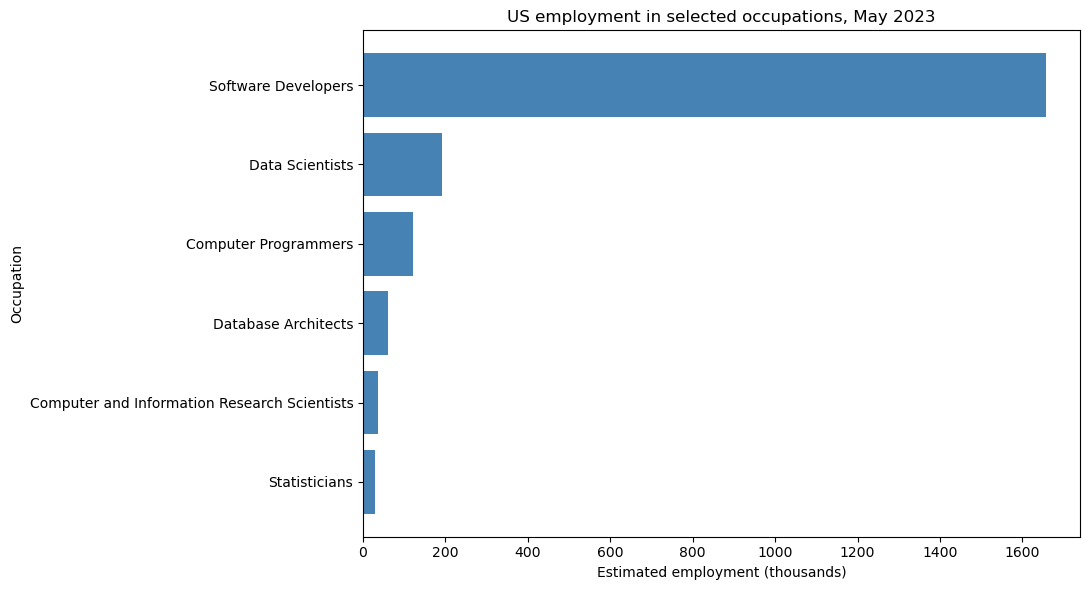

In [18]:
import matplotlib.pyplot as plt

employment = national.sort_values("TOT_EMP")

plt.figure(figsize=(11, 6))
plt.barh(
    employment["OCC_TITLE"],
    employment["TOT_EMP"] / 1000,
    color="steelblue"
)

plt.title("US employment in selected occupations, May 2023")
plt.xlabel("Estimated employment (thousands)")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

- **Objective:** To compare US employment across the six selected occupations in May 2023.

- **Why this type of visualisation was chosen:** A bar chart makes it easy to compare employment between occupations. Horizontal bars give enough space for the long job titles. Employment is shown in thousands to keep the numbers easy to read.

- **Learnings from this visualisation:** Software Developers had the highest employment, with 1,656,880 employees. Data Scientists had 192,710 employees, while Statisticians had the lowest figure at 29,950. This shows that software development had a much larger employment base than the other selected occupations. These figures cover whole occupations and do not show how many employees worked specifically in AI.

**Source:** BLS Occupational Employment and Wage Statistics, May 2023.

## 2. Box plot – State average annual pay by occupation

Rows used: 293
Rows excluded because pay is missing: 2


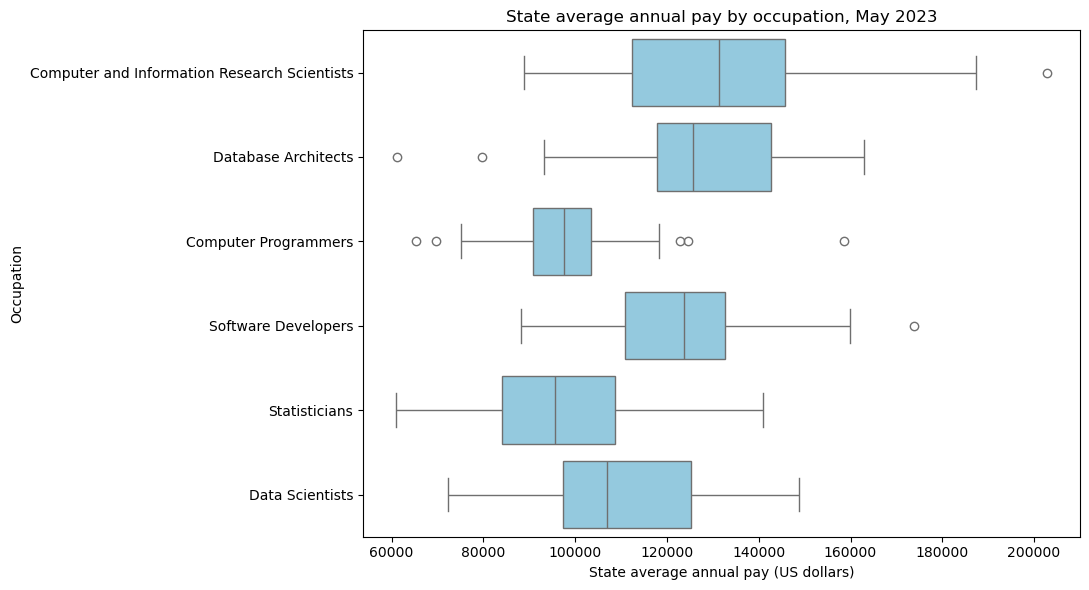

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Keep rows that have an average annual wage.
pay_data = states.dropna(subset=["A_MEAN"]).copy()

print("Rows used:", len(pay_data))
print("Rows excluded because pay is missing:", len(states) - len(pay_data))

# Comparing state average pay across the six occupations.
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=pay_data,
    x="A_MEAN",
    y="OCC_TITLE",
    color="skyblue"
)

plt.title("State average annual pay by occupation, May 2023")
plt.xlabel("State average annual pay (US dollars)")
plt.ylabel("Occupation")
plt.tight_layout()
plt.show()

In [20]:
# Summarising the state average wages for each occupation.
pay_summary = pay_data.groupby("OCC_TITLE")["A_MEAN"].describe()

pay_summary[
    ["count", "min", "25%", "50%", "75%", "max"]
].round(0)

,count,min,25%,50%,75%,max
OCC_TITLE,,,,,,
Computer Programmers,49.0,65320.0,90890.0,97480.0,103460.0,158520.0
Computer and Information Research Scientists,42.0,88770.0,112440.0,131240.0,145800.0,202910.0
Data Scientists,51.0,72220.0,97430.0,107000.0,125215.0,148730.0
Database Architects,51.0,61130.0,117865.0,125650.0,142595.0,162980.0
Software Developers,51.0,88130.0,110865.0,123700.0,132570.0,173780.0
Statisticians,49.0,60860.0,84000.0,95510.0,108720.0,140860.0


**Objective:** To compare how state average annual pay varies across the six selected occupations in May 2023.

**Why this type of visualisation was chosen:** A box plot shows the middle value, spread and unusually high or low values. This helps compare pay across occupations. The line inside each box shows the median of the state averages. The box contains the middle 50% of those averages.

**Learnings from this visualisation:** Computer and Information Research Scientists had the highest median of state average pay, at USD 131,240. Statisticians had the lowest, at USD 95,510. The figure for Data Scientists was USD 107,000, compared with USD 123,700 for Software Developers. Computer Programmers had the narrowest box, showing less variation within the middle 50% of state averages.

The comparison uses available state and DC averages. The number of reported areas differs between occupations. These figures show differences between areas and do not describe the pay distribution of individual employees.

**Source:** BLS Occupational Employment and Wage Statistics, May 2023.

## 3. Histogram – State average annual pay for Data Scientists

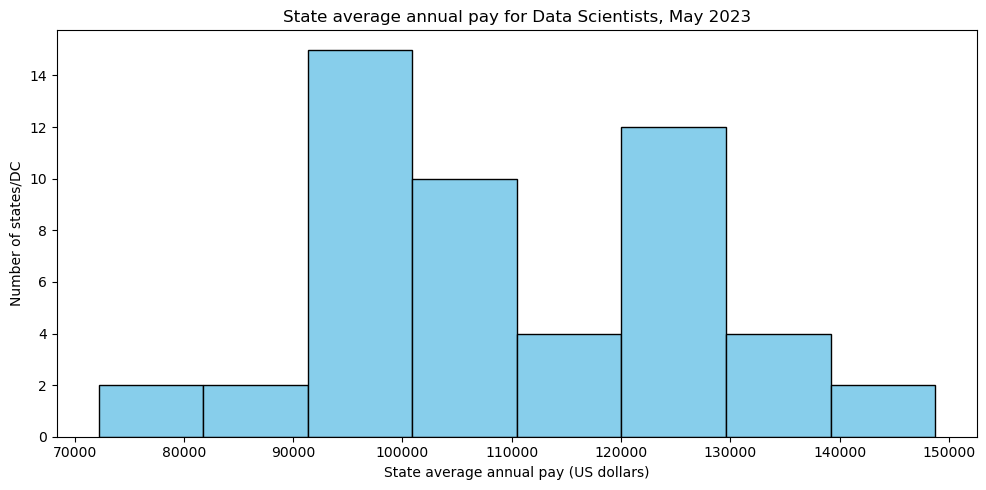

In [21]:
# Selected Data Scientists and kept available average wages.
data_scientists = states[states["OCC_CODE"] == "15-2051"]
data_scientist_pay = data_scientists["A_MEAN"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(
    data_scientist_pay,
    bins=8,
    color="skyblue",
    edgecolor="black"
)

plt.title("State average annual pay for Data Scientists, May 2023")
plt.xlabel("State average annual pay (US dollars)")
plt.ylabel("Number of states/DC")
plt.tight_layout()
plt.show()

In [22]:
data_scientist_pay.describe().round(0)

count        51.0
mean     110043.0
std       17137.0
min       72220.0
25%       97430.0
50%      107000.0
75%      125215.0
max      148730.0
Name: A_MEAN, dtype: float64

**Objective:** To examine the distribution of state average annual pay for Data Scientists across the 50 US states and DC in May 2023.

**Why this type of visualisation was chosen:** A histogram groups numerical pay values into intervals and shows how many areas fall within each interval. This makes common pay ranges and the spread of values easier to see. Eight intervals keep the chart clear for the 51 observations.

**Learnings from this visualisation:** The most common pay interval was approximately USD 91,000– USD 101,000. The median of the state/DC averages was USD 107,000. The lowest average was USD 72,220, while the highest was USD 148,730. These results show that average pay varied considerably between areas, even within the same occupation.

Each observation represents the average annual wage for one state or DC.

**Source:** BLS Occupational Employment and Wage Statistics, May 2023.

## 4. Correlation heatmap – Employment, pay and concentration

State/DC rows used: 49


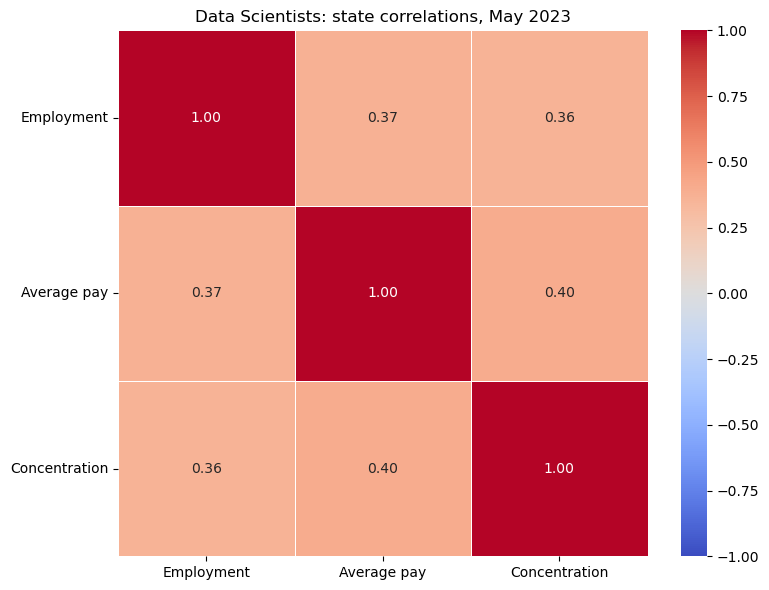

,Employment,Average pay,Concentration
Employment,1.00,0.37,0.36
Average pay,0.37,1.00,0.40
Concentration,0.36,0.40,1.00


In [23]:
# Selected three numerical measures for Data Scientists.
# Kept areas with values available for all three measures.
correlation_data = data_scientists[
    ["TOT_EMP", "A_MEAN", "LOC_QUOTIENT"]
].dropna()

# Using clearer labels in the chart.
correlation_data = correlation_data.rename(columns={
    "TOT_EMP": "Employment",
    "A_MEAN": "Average pay",
    "LOC_QUOTIENT": "Concentration"
})

# Calculated Pearson correlations.
corr = correlation_data.corr()

print("State/DC rows used:", len(correlation_data))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Data Scientists: state correlations, May 2023")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Showed the correlation values in a table.
corr.round(2)

**Objective:** To explore relationships between employment, average annual pay and employment concentration for Data Scientists across states and DC in May 2023.

**Why this type of visualisation was chosen:** A heatmap makes it easy to compare relationships between several numerical measures in one chart. The colours show the direction and strength of each relationship. The numbers show the Pearson correlation values.

**Learnings from this visualisation:** All three relationships were positive. Average pay and employment concentration had the highest correlation shown, at 0.40. Employment and average pay had a correlation of 0.37, while employment and concentration had a correlation of 0.36. Areas with higher employment or concentration tended to have higher average pay, although these relationships were not strong. Correlation does not show that one measure caused another to change.

The analysis uses 49 areas with values available for all three measures. Concentration measures the occupation’s share of local employment relative to its national share.

**Source:** BLS Occupational Employment and Wage Statistics, May 2023.

## 5. Scatter plot – Employment and average pay for Data Scientists

State/DC rows used: 49


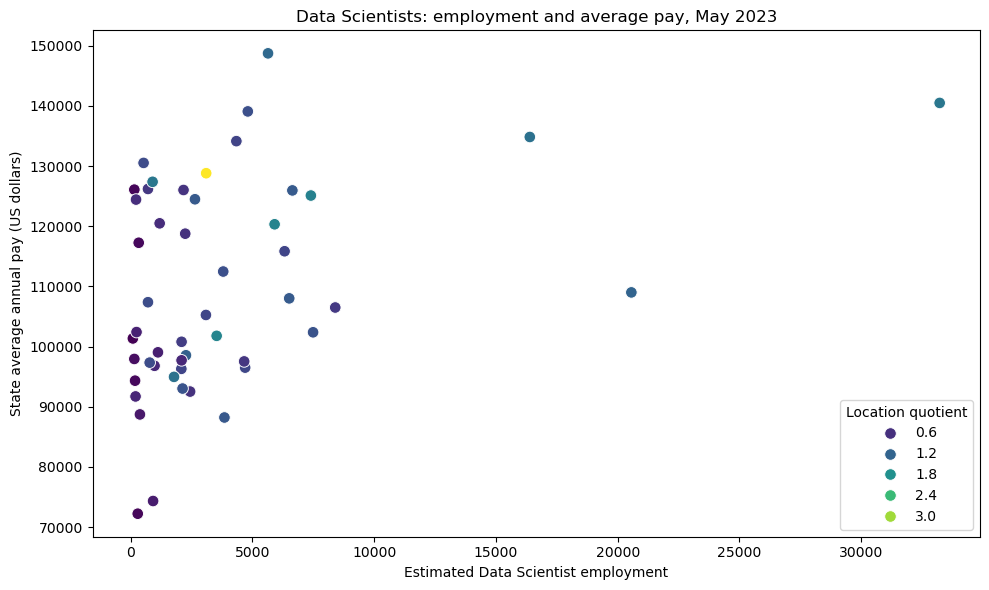

In [25]:
# Kept areas with employment, pay and concentration figures.
scatter_data = data_scientists.dropna(
    subset=["TOT_EMP", "A_MEAN", "LOC_QUOTIENT"]
).copy()

print("State/DC rows used:", len(scatter_data))

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=scatter_data,
    x="TOT_EMP",
    y="A_MEAN",
    hue="LOC_QUOTIENT",
    palette="viridis",
    s=70
)

plt.title("Data Scientists: employment and average pay, May 2023")
plt.xlabel("Estimated Data Scientist employment")
plt.ylabel("State average annual pay (US dollars)")
plt.legend(title="Location quotient")
plt.tight_layout()
plt.show()

In [26]:
scatter_data[
    ["AREA_TITLE", "TOT_EMP", "A_MEAN", "LOC_QUOTIENT"]
].sort_values("A_MEAN", ascending=False).head(5)

,AREA_TITLE,TOT_EMP,A_MEAN,LOC_QUOTIENT
181991,Washington,5640.0,148730.0,1.27
181948,California,33220.0,140490.0,1.46
181990,Virginia,4810.0,139080.0,0.95
181976,New York,16390.0,134830.0,1.38
181974,New Jersey,4340.0,134140.0,0.81


**Objective:** To explore the relationship between Data Scientist employment and average annual pay across states and DC in May 2023. Colour also shows employment concentration.

**Why this type of visualisation was chosen:** A scatter plot is suitable for comparing two numerical measures. Each point shows one area’s employment and average pay. This makes patterns, clusters and unusual observations easier to see. Colour adds the employment concentration measure.

**Learnings from this visualisation:** California had the highest employment shown, with 33,220 Data Scientists and average annual pay of USD 140,490. Washington had higher average pay, at USD 148,730, despite having fewer employees at 5,640. This shows that the area with the most Data Scientist jobs did not have the highest average pay. Areas with similar employment totals also had different pay levels and employment concentrations.

The chart includes 49 areas with all three measures available. It compares area averages and does not establish cause and effect.

**Source:** BLS Occupational Employment and Wage Statistics, May 2023.

## 6. Employment trends over time – 2022 to 2024

In [29]:
# Kept the existing 2023 national employment figures.
trend_2023 = national[
    ["OCC_CODE", "OCC_TITLE", "TOT_EMP"]
].copy()

trend_2023["Year"] = 2023

# Stored the yearly tables in a list.
trend_parts = [trend_2023]

columns_needed = [
    "AREA_TYPE", "NAICS", "OWN_CODE",
    "OCC_CODE", "OCC_TITLE", "O_GROUP", "TOT_EMP"
]

# Repeated the same loading and filtering steps for both new years.
for year in [2022, 2024]:
    print("Loading:", year)

    year_data = pd.read_excel(
        f"all_data_M_{year}.xlsx",
        sheet_name=f"All May {year} data",
        usecols=columns_needed,
        dtype=str,
        nrows=1300
    )

    year_national = year_data.loc[
        (year_data["AREA_TYPE"] == "1")
        & (year_data["NAICS"] == "000000")
        & (year_data["OWN_CODE"] == "1235")
        & (year_data["O_GROUP"] == "detailed")
        & year_data["OCC_CODE"].isin(occupation_codes),
        ["OCC_CODE", "OCC_TITLE", "TOT_EMP"]
    ].copy()

    year_national["TOT_EMP"] = pd.to_numeric(
        year_national["TOT_EMP"], errors="coerce"
    )

    year_national["Year"] = year
    trend_parts.append(year_national)

    print("National occupation rows:", len(year_national))

# Joined the yearly tables and put them in order.
trends = pd.concat(trend_parts, ignore_index=True)
trends = trends.sort_values(["OCC_TITLE", "Year"])

print("Combined rows:", len(trends))

trends[["Year", "OCC_TITLE", "TOT_EMP"]]

Loading: 2022
National occupation rows: 6
Loading: 2024
National occupation rows: 6
Combined rows: 18


,Year,OCC_TITLE,TOT_EMP
8,2022,Computer Programmers,132740.0
2,2023,Computer Programmers,120370.0
14,2024,Computer Programmers,109870.0
6,2022,Computer and Information Research Scientists,33780.0
0,2023,Computer and Information Research Scientists,35210.0
12,2024,Computer and Information Research Scientists,38480.0
11,2022,Data Scientists,159630.0
5,2023,Data Scientists,192710.0
17,2024,Data Scientists,233440.0
7,2022,Database Architects,62470.0


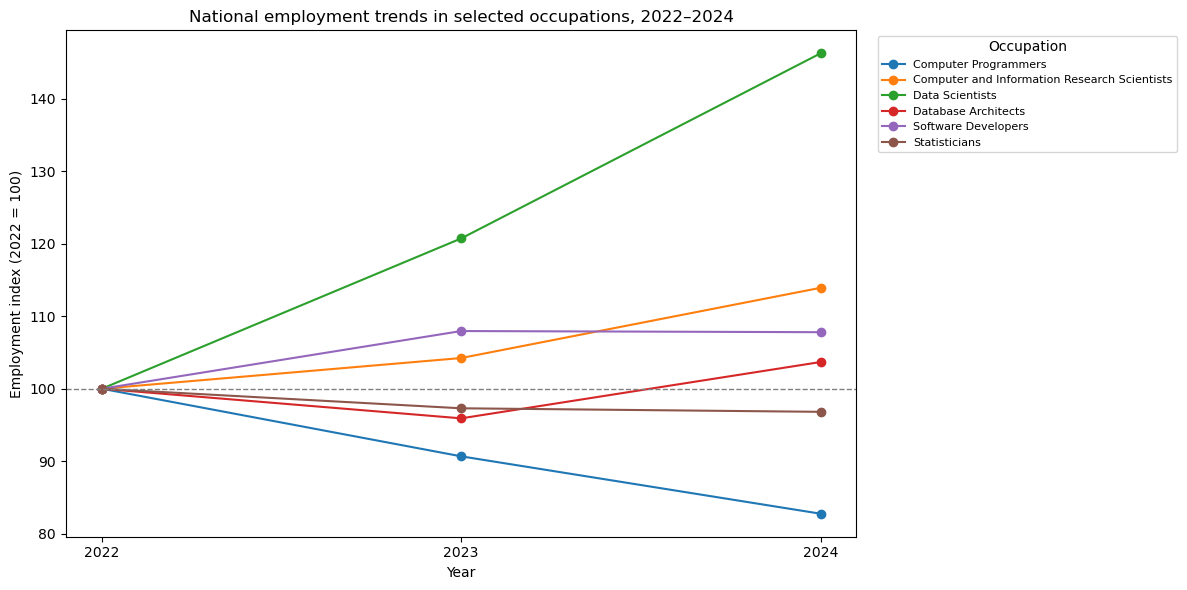

In [30]:
# Arranged the table with years in rows and occupations in columns.
employment_table = trends.pivot(
    index="Year",
    columns="OCC_TITLE",
    values="TOT_EMP"
).sort_index()

# Set the 2022 employment figure to 100 for each occupation.
employment_index = employment_table / employment_table.loc[2022] * 100

# Created the line chart.
employment_index.plot(figsize=(12, 6), marker="o")

plt.title("National employment trends in selected occupations, 2022–2024")
plt.xlabel("Year")
plt.ylabel("Employment index (2022 = 100)")
plt.xticks([2022, 2023, 2024])

# Showed the starting level.
plt.axhline(100, color="grey", linestyle="--", linewidth=1)

plt.legend(
    title="Occupation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [31]:
# Calculated the percentage change between 2022 and 2024.
change_percent = (
    employment_table.loc[2024] / employment_table.loc[2022] - 1
) * 100

change_percent.sort_values(ascending=False).round(2)

OCC_TITLE
Data Scientists                                 46.24
Computer and Information Research Scientists    13.91
Software Developers                              7.80
Database Architects                              3.68
Statisticians                                   -3.18
Computer Programmers                           -17.23
dtype: float64

**Objective:** To compare changes in national employment across the six selected occupations between May 2022 and May 2024.

**Why this type of visualisation was chosen:** A line chart shows how employment changes over time. Each occupation starts at 100 in 2022, which makes relative changes easier to compare despite their different employment totals. For example, an index of 120 means employment was 20% higher than in 2022.

**Learnings from this visualisation:** Data Scientists had the largest percentage increase, at 46.24%. Estimated employment rose from 159,630 in 2022 to 233,440 in 2024. Computer and Information Research Scientists increased by 13.91%, Software Developers by 7.80% and Database Architects by 3.68%. Computer Programmers decreased by 17.23%, while Statisticians decreased by 3.18%. These results show different employment patterns across the selected occupations.

**Limitations:** These figures cover whole occupations and do not identify jobs involving only AI. They do not show whether AI caused the changes. BLS estimates combine survey data collected over three years, with overlapping samples between annual releases. Comparisons over this short period therefore need care (Bureau of Labor Statistics, 2026).

**Sources:** BLS Occupational Employment and Wage Statistics, May 2022, May 2023 and May 2024, available from the [BLS data tables](https://www.bls.gov/oes/tables.htm). Methodological guidance: [BLS Frequently Asked Questions](https://www.bls.gov/oes/oes_ques.htm).

## 7. References

Bureau of Labor Statistics (2023) *Occupational Employment and Wage Statistics, May 2022: All data* [dataset]. Available at: [https://www.bls.gov/oes/special-requests/oesm22all.zip](https://www.bls.gov/oes/special-requests/oesm22all.zip) (Accessed: 8 November 2026).

Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023: All data* [dataset]. Available at: [https://www.bls.gov/oes/special-requests/oesm23all.zip](https://www.bls.gov/oes/special-requests/oesm23all.zip) (Accessed: 7 November 2026).

Bureau of Labor Statistics (2025) *Occupational Employment and Wage Statistics, May 2024: All data* [dataset]. Available at: [https://www.bls.gov/oes/special-requests/oesm24all.zip](https://www.bls.gov/oes/special-requests/oesm24all.zip) (Accessed: 8 November 2026).

Bureau of Labor Statistics (2026) *Occupational Employment and Wage Statistics: Frequently asked questions*. Available at: [https://www.bls.gov/oes/oes_ques.htm](https://www.bls.gov/oes/oes_ques.htm) (Accessed: 9 November 2026).

pandas (n.d.a) *pandas.DataFrame.drop_duplicates*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html (Accessed: 8 November 2026).

pandas (n.d.b) *pandas.DataFrame.dropna*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html (Accessed: 8 November 2026).

pandas (n.d.c) *pandas.DataFrame.loc*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.loc.html (Accessed: 8 November 2026).

pandas (n.d.d) *pandas.read_excel*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html (Accessed: 9 November 2026).

pandas (n.d.e) *pandas.Series.isin*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html (Accessed: 9 November 2026).

pandas (n.d.f) *pandas.to_numeric*. Available at: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html (Accessed: 9 November 2026).
